<style>
.custom-spacing {
    line-height: 0.5;
}
</style>

### <center>**PENERAPAN PROMT AI UNTUK ANALISIS DAN INTERPRETASI DATA GEOFISIKA**</center>

<div style="text-align:center;">
  <img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" alt="Deskripsi Gambar" style="width:280px;">
</div>

### <center>*DISUSUN OLEH :*</center>
### <center>**HERLINDA SIMAN**</center>
### <center>**H061241036**<center>






















### <center>**PROGRAM STUDI GEOFISIKA**</center>
### <center>**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**</center>
#### <center>**UNIVERSITAS HASANUDDIN**</center>
#### <center>**MAKASSAR**</center>
#### <center>**2025**</center>

<hr>

# TUGAS KECERDASAN ARTIFISIAL UNTUK GEOFISIKA
### Merancang Prompt AI untuk Kasus-Kasus Geofisika dengan Kerangka R–T–C–I–K–O–Q–V

---
![Screenshot 2026-09-29 211648.png](<attachment:Screenshot 2026-09-29 211648.png>)

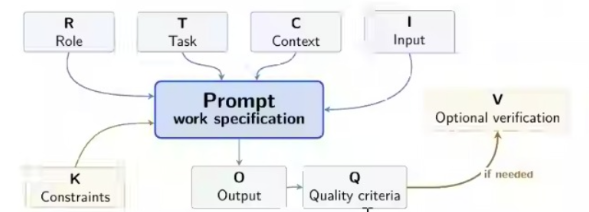

## Tentang Kerangka R–T–C–I–K–O–Q–V

Dalam menyusun instruksi (prompt) untuk AI agar hasilnya terarah dan tidak asal-asalan, digunakan delapan elemen berikut. Setiap prompt pada tugas ini disusun mengikuti kedelapan elemen tersebut secara berurutan.

| Kode | Elemen | Fungsi dalam Prompt |
|---|---|---|
| R | Role | Menentukan "siapa" AI diminta berperan |
| T | Task | Menjabarkan pekerjaan inti yang harus diselesaikan |
| C | Context | Memberi latar belakang agar AI paham situasi persoalan |
| I | Input | Menjelaskan data/materi yang tersedia untuk diproses |
| K | Constraints | Aturan main / batasan yang tidak boleh dilanggar |
| O | Output | Bentuk dan isi keluaran yang diharapkan |
| Q | Quality Criteria | Standar yang menentukan jawaban dianggap baik |
| V | Verification | Langkah pengecekan ulang sebelum jawaban difinalisasi |

Berikut lima prompt yang disusun untuk lima permasalahan geofisika yang berbeda.


## Prompt 1 — Interpretasi Sounding Geolistrik untuk Identifikasi Akuifer

Prompt ini disiapkan untuk kasus eksplorasi air tanah menggunakan metode geolistrik resistivitas (VES).

**ROLE**
Bertindaklah sebagai geofisikawan eksplorasi yang berpengalaman menangani survei geolistrik resistivitas.

**TASK**
Interpretasikan kurva sounding geolistrik (Vertical Electrical Sounding) untuk memperoleh jumlah lapisan bawah permukaan beserta nilai resistivitasnya, lalu tentukan lapisan mana yang berpotensi sebagai akuifer.

**CONTEXT**
Survei ini dilakukan di lokasi yang diduga memiliki potensi air tanah. Variasi resistivitas antar lapisan mencerminkan perbedaan litologi dan kandungan fluida, sehingga dapat dipakai untuk menduga posisi akuifer sebelum dilakukan pemboran.

**INPUT**
- Data AB/2 (jarak elektroda arus) dan nilai resistivitas semu hasil pengukuran lapangan.
- Informasi geologi permukaan/regional di sekitar titik sounding (apabila tersedia).

**CONSTRAINTS**
1. Interpretasi lapisan wajib bersumber dari bentuk kurva yang diberikan, bukan asumsi bebas.
2. Sertakan penjelasan singkat mengenai tahap pencocokan kurva (curve matching/inversi).
3. Pisahkan dengan jelas mana bagian "pembacaan data" dan mana bagian "interpretasi geologi".
4. Nilai resistivitas dilaporkan konsisten dalam satuan ohm-meter.

**OUTPUT YANG DIHARAPKAN**
a. Ringkasan data sounding yang dianalisis
b. Model lapisan (jumlah lapisan, ketebalan, resistivitas)
c. Lapisan yang diduga sebagai akuifer beserta alasannya
d. Paragraf interpretasi
e. Tabel rangkuman hasil

**KRITERIA KUALITAS**
Hasil dinilai baik apabila konsisten dengan pola kurva, istilah geolistrik digunakan secara tepat, dan tidak ada klaim litologi yang berlebihan dari data yang terbatas.

**VERIFIKASI**
Sebelum jawaban akhir disampaikan, cek ulang apakah model lapisan cocok dengan bentuk kurva, dan apakah rentang resistivitas yang disebut wajar untuk jenis material yang dimaksud.


,AB/2 (m),Resistivitas semu (ohm-m)
0,1.0,259.9
1,1.5,254.0
2,2.0,225.7
3,3.0,179.4
4,4.0,137.4
5,6.0,84.3
6,8.0,60.6
7,12.0,45.8
8,16.0,41.8
9,24.0,56.9


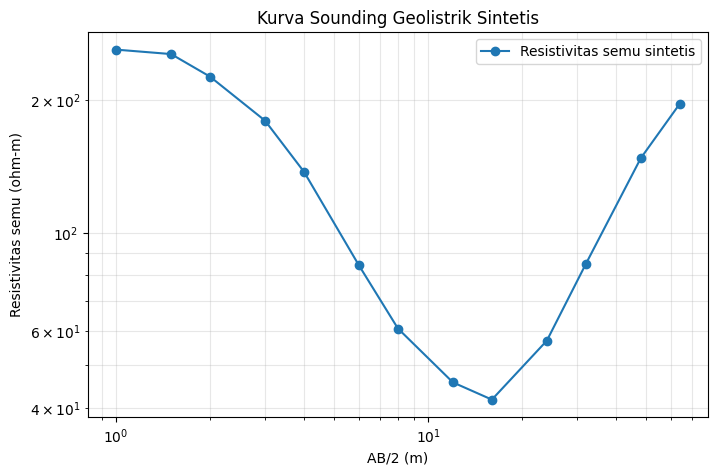

Nilai terendah: 41.8 ohm-m pada AB/2 = 16 m
Nilai tertinggi: 259.9 ohm-m pada AB/2 = 1 m


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data sounding sintetis (bukan pengukuran lapangan)
ab2 = np.array([1, 1.5, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64], dtype=float)
rho_true = np.array([260, 245, 220, 175, 130, 88, 62, 48, 42, 55, 85, 145, 210], dtype=float)
rng = np.random.default_rng(12)
rho_app = rho_true * (1 + rng.normal(0, 0.035, len(rho_true)))

sounding = pd.DataFrame({"AB/2 (m)": ab2, "Resistivitas semu (ohm-m)": rho_app.round(1)})
display(sounding)

plt.figure(figsize=(8, 5))
plt.loglog(ab2, rho_app, "o-", label="Resistivitas semu sintetis")
plt.xlabel("AB/2 (m)")
plt.ylabel("Resistivitas semu (ohm-m)")
plt.title("Kurva Sounding Geolistrik Sintetis")
plt.grid(True, which="both", alpha=.3)
plt.legend()
plt.show()

imin, imax = int(np.argmin(rho_app)), int(np.argmax(rho_app))
print(f"Nilai terendah: {rho_app[imin]:.1f} ohm-m pada AB/2 = {ab2[imin]:g} m")
print(f"Nilai tertinggi: {rho_app[imax]:.1f} ohm-m pada AB/2 = {ab2[imax]:g} m")

### Interpretasi Prompt 1
Kurva contoh memperlihatkan penurunan resistivitas semu dari jarak AB/2 kecil menuju nilai minimum, kemudian meningkat kembali. Bagian dengan resistivitas relatif rendah **dapat menjadi kandidat zona konduktif**, yang mungkin berhubungan dengan material lempungan atau material jenuh air. Resistivitas rendah tidak otomatis berarti akuifer karena lempung juga dapat menghasilkan nilai rendah.

Model jumlah lapisan, ketebalan, dan resistivitas sebenarnya perlu diperoleh melalui curve matching/inversi serta dikontrol dengan data geologi atau sumur. Jadi, dari contoh sintetis ini hanya dapat disampaikan dugaan awal, bukan penetapan lapisan akuifer yang pasti.


---

## Prompt 2 — Pembacaan Radargram GPR untuk Deteksi Struktur Dangkal

Digunakan untuk kasus investigasi bawah permukaan dangkal dengan metode Ground Penetrating Radar.

**ROLE**
Anda adalah spesialis metode Ground Penetrating Radar (GPR) yang biasa menangani survei dangkal (near-surface).

**TASK**
Baca radargram hasil akuisisi GPR, kenali pola-pola reflektor yang muncul, dan berikan dugaan mengenai struktur atau objek yang menyebabkan pola tersebut.

**CONTEXT**
GPR memancarkan gelombang elektromagnetik yang akan dipantulkan kembali ketika bertemu perbedaan sifat dielektrik material. Survei semacam ini lazim dipakai untuk mencari rongga, pipa bawah tanah, atau memetakan lapisan tanah dangkal.

**INPUT**
- Citra radargram (sumbu waktu rambat dua arah / two-way travel time)
- Perkiraan kecepatan rambat gelombang pada medium, bila diketahui
- Lokasi/koordinat lintasan pengukuran, bila tersedia

**CONSTRAINTS**
- Reflektor hanya boleh disebutkan bila memang tampak jelas polanya pada radargram.
- Jangan langsung menyimpulkan "objek ini pasti pipa/rongga" tanpa dasar yang cukup — gunakan kata "diduga" atau "kemungkinan".
- Jelaskan dasar konversi dari waktu rambat ke estimasi kedalaman.
- Bedakan hasil pembacaan sinyal dari tafsiran objek/struktur.

**OUTPUT YANG DIHARAPKAN**
1. Gambaran umum radargram
2. Daftar reflektor signifikan yang teridentifikasi
3. Estimasi kedalaman masing-masing reflektor
4. Dugaan struktur/objek penyebab reflektor
5. Paragraf pembahasan
6. Simpulan akhir

**KRITERIA KUALITAS**
Pembacaan sinyal harus runtut, estimasi kedalaman masuk akal terhadap asumsi kecepatan yang dipakai, dan bahasa yang digunakan tidak berlebihan (overclaim).

**VERIFIKASI**
Cek kembali apakah estimasi kedalaman sudah sesuai dengan kecepatan gelombang yang diasumsikan, dan apakah tafsiran objek konsisten dengan bentuk reflektor yang tampak.


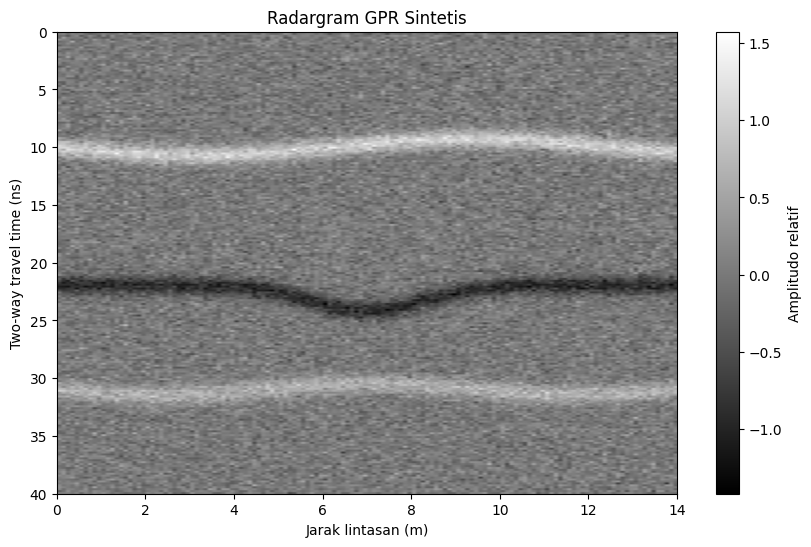

,Reflektor,TWT (ns),Asumsi kecepatan (m/ns),Estimasi kedalaman (m)
0,R1,10.0,0.1,0.50
1,R2,22.0,0.1,1.10
2,R3,31.0,0.1,1.55


In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(21)
n_traces, n_samples = 140, 240
twt_ns = np.linspace(0, 40, n_samples)
distance_m = np.linspace(0, 14, n_traces)
radar = rng.normal(0, 0.18, (n_samples, n_traces))

# Reflektor sintetis: waktu tiba dan amplitudo berubah sepanjang lintasan
for j, x in enumerate(distance_m):
    events = [
        (10 + 0.7*np.sin(x/2), 1.0),
        (22 + 2.2*np.exp(-((x-7)/1.8)**2), -0.9),
        (31 + 0.5*np.sin(x/1.5), 0.65)
    ]
    for t0, amp in events:
        radar[:, j] += amp * np.exp(-0.5*((twt_ns-t0)/0.55)**2)

plt.figure(figsize=(10, 6))
plt.imshow(radar, cmap="gray", aspect="auto",
           extent=[distance_m.min(), distance_m.max(), twt_ns.max(), twt_ns.min()])
plt.xlabel("Jarak lintasan (m)")
plt.ylabel("Two-way travel time (ns)")
plt.title("Radargram GPR Sintetis")
plt.colorbar(label="Amplitudo relatif")
plt.show()

v_m_per_ns = 0.10
reflector_twt = np.array([10, 22, 31], dtype=float)
depths = v_m_per_ns * reflector_twt / 2
pd.DataFrame({
    "Reflektor": ["R1", "R2", "R3"],
    "TWT (ns)": reflector_twt,
    "Asumsi kecepatan (m/ns)": v_m_per_ns,
    "Estimasi kedalaman (m)": depths
}).round(2)

### Interpretasi Prompt 2
Radargram sintetis memperlihatkan tiga reflektor utama yang relatif menerus, dengan reflektor kedua mengalami perubahan bentuk di bagian tengah lintasan. Dengan asumsi kecepatan 0,10 m/ns, estimasi kedalamannya masing-masing sekitar 0,50 m, 1,10 m, dan 1,55 m.

Perubahan reflektor dapat berkaitan dengan perubahan sifat dielektrik atau batas material bawah permukaan. Namun, bentuk ini tidak cukup untuk memastikan keberadaan pipa, rongga, atau jenis lapisan tertentu. Kedalaman sangat bergantung pada kecepatan yang diasumsikan; validasi idealnya menggunakan pengukuran kecepatan setempat dan informasi lapangan.

---

## Prompt 3 — Estimasi Episenter dari Data Multi-Stasiun Seismik

Prompt ini menyasar persoalan lokasi sumber gempa memakai data gabungan beberapa stasiun pencatat.

**Peran (Role)**
Berperan sebagai ahli seismologi sekaligus asisten praktikum bagi mahasiswa S1 Geofisika.

**Tugas (Task)**
Tentukan waktu tiba gelombang P dan S pada tiap stasiun perekam, lalu gunakan data dari minimal tiga stasiun tersebut untuk mengestimasi posisi episenter dan, jika memungkinkan, kedalaman sumber gempa.

**Konteks (Context)**
Penentuan episenter yang akurat memerlukan kombinasi data dari beberapa stasiun agar ketidakpastian lokasi dapat diperkecil (metode trilaterasi). Tugas ini merupakan bagian dari praktikum Seismologi.

**Input**
- Rekaman seismogram dari ≥3 stasiun berbeda
- Koordinat masing-masing stasiun
- Kecepatan rambat gelombang P dan S rata-rata (jika diketahui)

**Batasan (Constraints)**
- Waktu tiba P dan S wajib diambil dari pola yang benar-benar tampak di seismogram, tidak boleh direka-reka.
- Tunjukkan langkah perhitungan jarak episenter–stasiun untuk setiap stasiun secara terpisah.
- Jelaskan logika trilaterasi/triangulasi yang dipakai untuk menggabungkan hasil dari ketiga stasiun.
- Satuan waktu, kecepatan, dan jarak harus konsisten di seluruh perhitungan.

**Output**
1. Tabel waktu tiba P, S, dan selisihnya per stasiun
2. Perhitungan jarak tiap stasiun ke sumber gempa
3. Estimasi koordinat episenter
4. Estimasi kedalaman (bila data mendukung)
5. Paragraf interpretasi hasil

**Kriteria Kualitas (Q)**
Perhitungan antar stasiun harus saling konsisten, metode triangulasi dijelaskan secara logis, dan seluruh proses dapat ditelusuri ulang oleh mahasiswa.

**Verifikasi (V)**
Bandingkan hasil estimasi episenter dari kombinasi ketiga stasiun; pastikan tidak ada penyimpangan satuan atau kesalahan aritmetika sebelum hasil akhir disampaikan.


,Stasiun,X (km),Y (km),tP (s),tS (s),S-P (s),Jarak perkiraan (km)
0,STA-A,0.0,0.0,9.71,13.08,3.37,28.28
1,STA-B,40.0,0.0,9.71,13.08,3.37,28.28
2,STA-C,10.0,35.0,8.00,10.15,2.15,18.03


Posisi terbaik pada grid ilustratif: X=20.0 km, Y=20.0 km
Sumber pembangkit data sintetis berada di X=20.0 km, Y=20.0 km.
Kedekatan keduanya menguji bahwa contoh sintetis dan perhitungan jarak konsisten.


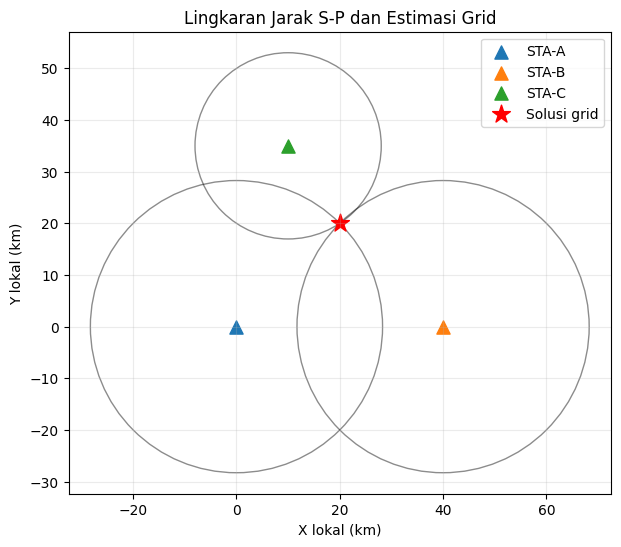

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Koordinat lokal sintetis; sumber contoh dipakai hanya untuk membangun data konsisten
source_x, source_y = 20.0, 20.0
stations = pd.DataFrame({
    "Stasiun": ["STA-A", "STA-B", "STA-C"],
    "X (km)": [0.0, 40.0, 10.0],
    "Y (km)": [0.0, 0.0, 35.0]
})
vp, vs = 6.0, 3.5  # kecepatan rata-rata asumsi (km/s)
stations["Jarak sintetis (km)"] = np.sqrt(
    (stations["X (km)"]-source_x)**2 + (stations["Y (km)"]-source_y)**2
)
stations["tP (s)"] = stations["Jarak sintetis (km)"] / vp + 5.0
stations["tS (s)"] = stations["Jarak sintetis (km)"] / vs + 5.0
stations["S-P (s)"] = stations["tS (s)"] - stations["tP (s)"]
stations["Jarak perkiraan (km)"] = stations["S-P (s)"] / (1/vs - 1/vp)
display(stations[["Stasiun", "X (km)", "Y (km)", "tP (s)", "tS (s)", "S-P (s)", "Jarak perkiraan (km)"]].round(2))

# Estimasi titik grid dengan meminimalkan selisih kuadrat jarak
xg = np.linspace(-30, 70, 201)
yg = np.linspace(-30, 70, 201)
X, Y = np.meshgrid(xg, yg)
misfit = np.zeros_like(X)
for _, row in stations.iterrows():
    rcalc = np.sqrt((X-row["X (km)"])**2 + (Y-row["Y (km)"])**2)
    misfit += (rcalc-row["Jarak perkiraan (km)"])**2
iy, ix = np.unravel_index(np.argmin(misfit), misfit.shape)
xe, ye = X[iy, ix], Y[iy, ix]
print(f"Posisi terbaik pada grid ilustratif: X={xe:.1f} km, Y={ye:.1f} km")
print(f"Sumber pembangkit data sintetis berada di X={source_x:.1f} km, Y={source_y:.1f} km.")
print("Kedekatan keduanya menguji bahwa contoh sintetis dan perhitungan jarak konsisten.")

fig, ax = plt.subplots(figsize=(7, 6))
for _, row in stations.iterrows():
    ax.scatter(row["X (km)"], row["Y (km)"], marker="^", s=90, label=row["Stasiun"])
    ax.add_patch(plt.Circle((row["X (km)"], row["Y (km)"]),
                            row["Jarak perkiraan (km)"], fill=False, alpha=.45))
ax.scatter(xe, ye, marker="*", s=180, color="red", label="Solusi grid")
ax.set_xlabel("X lokal (km)"); ax.set_ylabel("Y lokal (km)")
ax.set_title("Lingkaran Jarak S-P dan Estimasi Grid")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=.25); ax.legend()
plt.show()

### Interpretasi Prompt 3
Selisih waktu S–P digunakan untuk memperkirakan jarak relatif sumber gempa dari tiap stasiun. Secara umum, selisih S–P yang lebih besar menunjukkan jarak yang lebih jauh jika kecepatan rata-rata dianggap sama. Lingkaran pada gambar menunjukkan jarak perkiraan dari masing-masing stasiun, sedangkan bintang merupakan titik pada grid yang meminimalkan selisih kuadrat jarak.

Karena data waktu tiba sengaja dibuat untuk demonstrasi dan model hanya menggunakan jarak horizontal, hasil koordinat tidak mewakili episenter kejadian nyata. Kedalaman sumber belum dapat ditentukan dengan baik dari contoh ini; diperlukan waktu tiba yang dipicking dari seismogram, model kecepatan yang sesuai, dan inversi hiposenter.

---

## Prompt 4 — Menyusun Peta Kerawanan Longsor dari Analisis Lereng (DEM)

Prompt untuk kajian kebencanaan geologi berbasis data topografi digital.

**[ROLE]**
Posisikan diri Anda sebagai analis SIG (Sistem Informasi Geografis) yang berfokus pada kajian bahaya geologi.

**[TASK]**
Olah data DEM menjadi peta kemiringan lereng, klasifikasikan ke dalam beberapa kelas kecuraman, kemudian pakai hasil tersebut sebagai salah satu input untuk menyusun peta tingkat kerawanan longsor di wilayah kajian.

**[CONTEXT]**
Longsor umumnya dipicu oleh kombinasi beberapa faktor, dan kemiringan lereng adalah salah satu faktor dominan. Dengan menggabungkan peta lereng bersama data pendukung lain, tingkat kerawanan suatu wilayah dapat dipetakan secara spasial.

**[INPUT]**
- Raster DEM wilayah kajian
- Batas administrasi/batas wilayah kajian
- Data pendukung tambahan seperti jenis tanah atau intensitas curah hujan (opsional, bila tersedia)
- Perangkat lunak yang digunakan: ArcGIS/ArcMap

**[CONSTRAINTS]**
- Proses wajib dimulai dari DEM asli, bukan data turunan yang tidak jelas asalnya.
- Sistem koordinat pada seluruh layer harus disamakan sebelum diproses.
- Lakukan Clip/Extract by Mask terlebih dahulu bila DEM mencakup area lebih luas dari wilayah kajian.
- Gunakan tool "Slope" (bukan tool lain) untuk menghitung kemiringan lereng.
- Jika parameter lain digabungkan dengan lereng, jelaskan bobot/skema pembobotan yang dipakai.
- Kesimpulan kerawanan tidak boleh melebihi apa yang bisa dijustifikasi oleh data yang ada.

**[OUTPUT]**
i. Tahapan pengolahan di ArcMap secara berurutan
ii. Peta/raster kemiringan lereng beserta kelas-kelasnya
iii. Cara penggabungan lereng dengan parameter lain (bila ada)
iv. Peta atau uraian tingkat kerawanan longsor
v. Pembahasan pola kerawanan yang muncul
vi. Kesimpulan
vii. Rekomendasi elemen kartografis (legenda, skala, arah utara, grid, sumber data)

**[QUALITY CRITERIA]**
Urutan proses harus sesuai kaidah kerja ArcMap, nama tool disebut dengan benar, dan tingkat kerawanan yang disimpulkan sejalan dengan pola pada peta yang dihasilkan.

**[VERIFICATION]**
Periksa ulang kesesuaian sistem koordinat, satuan derajat/persen pada lereng, kesesuaian kelas kerawanan dengan input yang digunakan, dan kelengkapan elemen peta sebelum disimpulkan final.


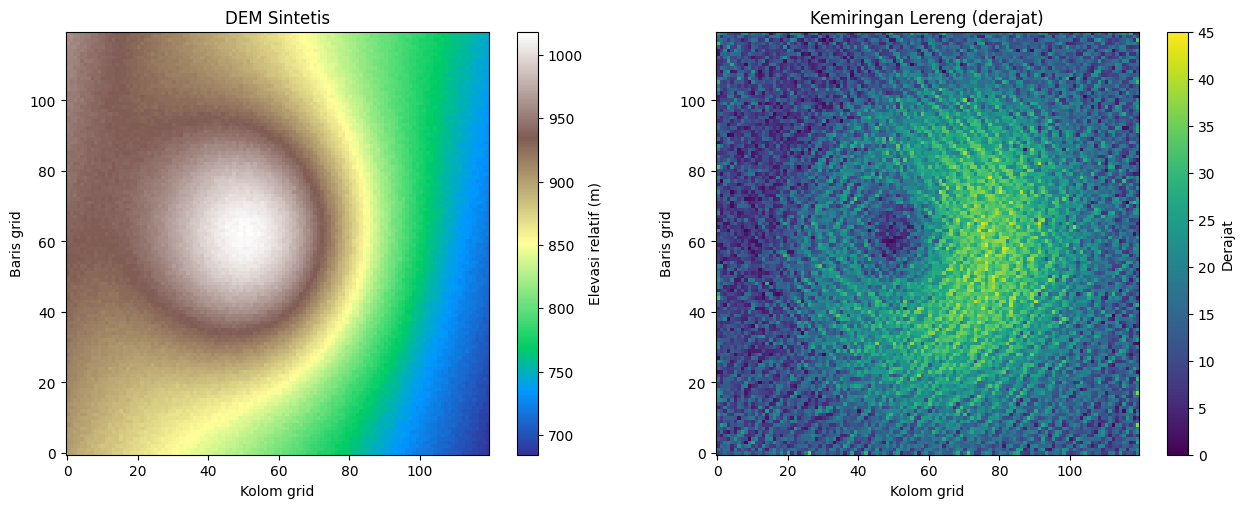

,Kelas lereng,Jumlah sel,Persentase (%)
0,0–8°,1886,13.10
1,8–15°,4235,29.41
2,15–25°,5519,38.33
3,25–45°,2760,19.17
4,>45°,0,0.00


Catatan: kelas lereng bukan peta kerawanan longsor final.


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# DEM sintetis dengan satu punggungan dan lembah; ukuran sel 10 m
rng = np.random.default_rng(7)
n = 120
cellsize = 10.0
x = np.arange(n) * cellsize
y = np.arange(n) * cellsize
X, Y = np.meshgrid(x, y)
dem = (900 + 180*np.exp(-((X-550)**2/(2*220**2) + (Y-600)**2/(2*260**2)))
       - 0.18*X + 0.05*Y + rng.normal(0, 1.5, (n, n)))

# Gradien elevasi dan slope dalam derajat
dz_dy, dz_dx = np.gradient(dem, cellsize, cellsize)
slope_deg = np.degrees(np.arctan(np.sqrt(dz_dx**2 + dz_dy**2)))
bins = [0, 8, 15, 25, 45, 90]
labels = ["0–8°", "8–15°", "15–25°", "25–45°", ">45°"]
slope_class = np.digitize(slope_deg, bins[1:-1])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im0 = axes[0].imshow(dem, origin="lower", cmap="terrain")
axes[0].set_title("DEM Sintetis"); axes[0].set_xlabel("Kolom grid"); axes[0].set_ylabel("Baris grid")
plt.colorbar(im0, ax=axes[0], label="Elevasi relatif (m)")
im1 = axes[1].imshow(slope_deg, origin="lower", cmap="viridis", vmin=0, vmax=45)
axes[1].set_title("Kemiringan Lereng (derajat)"); axes[1].set_xlabel("Kolom grid"); axes[1].set_ylabel("Baris grid")
plt.colorbar(im1, ax=axes[1], label="Derajat")
plt.tight_layout(); plt.show()

counts = np.bincount(slope_class.ravel(), minlength=5)
summary = pd.DataFrame({"Kelas lereng": labels, "Jumlah sel": counts,
                        "Persentase (%)": counts/counts.sum()*100})
display(summary.round(2))
print("Catatan: kelas lereng bukan peta kerawanan longsor final.")

### Interpretasi Prompt 4
Peta slope memperlihatkan variasi kecuraman pada DEM sintetis. Area dengan nilai slope lebih besar menunjukkan perubahan elevasi yang lebih cepat dalam jarak horizontal yang sama. Tabel persentase merangkum sebaran sel pada setiap kelas kemiringan.

Lereng curam dapat meningkatkan potensi ketidakstabilan, tetapi slope saja tidak cukup untuk menentukan tingkat kerawanan longsor. Karena DEM ini buatan dan belum digabungkan dengan curah hujan, litologi, penggunaan lahan, serta inventaris longsor, hasilnya hanya demonstrasi analisis topografi dan tidak dapat dipakai sebagai peta bahaya untuk wilayah administrasi tertentu.

---

## Prompt 5 — Klasifikasi Fasies Seismik Berbasis Machine Learning

Prompt untuk penerapan pembelajaran mesin pada interpretasi seismik.

**Role :** Praktisi geofisika eksplorasi yang terbiasa mengintegrasikan machine learning ke alur kerja interpretasi seismik.

**Task :** Bangun/klasifikasikan fasies seismik dari atribut seismik yang diberikan menggunakan pendekatan machine learning, lalu jelaskan ciri khas tiap kelas fasies yang terbentuk.

**Context :** Fasies seismik menggambarkan kelompok pola refleksi dengan karakter serupa yang bisa mengindikasikan lingkungan pengendapan tertentu. Pendekatan machine learning dipilih agar proses pengelompokan lebih cepat dan konsisten dibanding interpretasi visual manual sepenuhnya.

**Input :** Atribut seismik (contoh: amplitudo, frekuensi sesaat, koherensi, atau atribut lainnya), disertai label fasies untuk data latih apabila tersedia.

**Constraints :**
- Sebutkan algoritma machine learning yang dipilih beserta alasan pemilihannya untuk kasus ini.
- Akurasi/performa model tidak boleh diklaim tanpa disertai metrik evaluasi.
- Pisahkan secara eksplisit antara "hasil klasifikasi statistik" dan "tafsiran geologinya".
- Sebutkan atribut mana yang paling berkontribusi terhadap pemisahan kelas.
- Ungkapkan keterbatasan model apabila jumlah data latih sedikit atau tidak seimbang antar kelas.

**Output :**
1. Ringkasan data dan atribut seismik yang dipakai
2. Penjelasan algoritma dan alur pelatihan model
3. Hasil klasifikasi fasies (jumlah kelas dan sebarannya)
4. Evaluasi performa model (akurasi, confusion matrix, atau metrik lain yang relevan)
5. Tafsiran geologi untuk tiap kelas fasies
6. Kesimpulan

**Quality Criteria :** Proses pemodelan dijelaskan secara terbuka (bukan black box), evaluasi kuantitatif disertakan, dan tafsiran geologi berpijak pada hasil klasifikasi yang sudah tervalidasi.

**Verification :** Cek kembali kesesuaian hasil klasifikasi terhadap data asli, tinjau ulang metrik evaluasi model, dan pastikan tafsiran geologi tiap kelas fasies masih masuk akal secara konsep.


,Amplitudo relatif,Frekuensi (Hz),Koherensi
0,0.281870,20.311530,0.841218
1,0.253369,17.287298,0.870116
2,0.242170,23.859407,0.928578
3,0.271474,18.776594,0.752331
4,0.331346,17.629695,0.818451


Jumlah sampel: 300
Jumlah anggota per cluster:


,Jumlah sampel
Cluster,
0,100
1,100
2,100


Perkiraan silhouette score dari sampel: 0.697


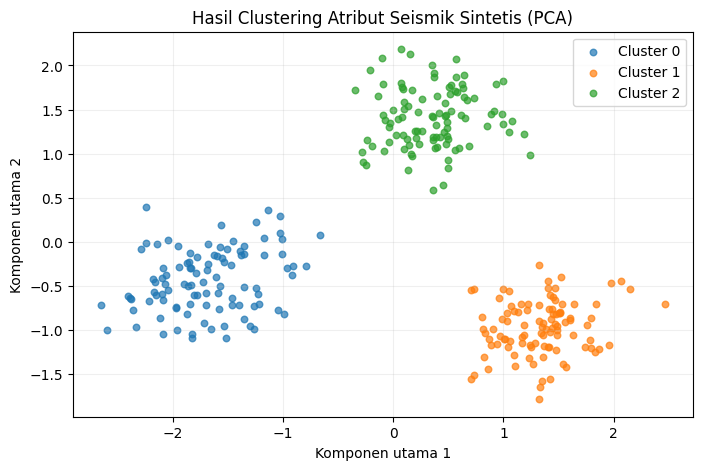

Rata-rata atribut tiap cluster:


,Amplitudo relatif,Frekuensi (Hz),Koherensi
Cluster,,,
0,0.756,35.396,0.451
1,0.259,21.867,0.797
2,0.457,15.927,0.237


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(33)
# Tiga kelompok atribut sintetis untuk demonstrasi
n_per = 100
means = np.array([[0.25, 22, 0.80], [0.75, 35, 0.45], [0.45, 16, 0.25]])
stds = np.array([[0.08, 3, 0.07], [0.10, 4, 0.08], [0.09, 2.5, 0.08]])
groups = [rng.normal(means[i], stds[i], (n_per, 3)) for i in range(3)]
data = np.vstack(groups)
df = pd.DataFrame(data, columns=["Amplitudo relatif", "Frekuensi (Hz)", "Koherensi"])
display(df.head())

# Standardisasi fitur menggunakan NumPy (tanpa scikit-learn)
mu = data.mean(axis=0)
sigma = data.std(axis=0)
scaled = (data - mu) / np.where(sigma == 0, 1, sigma)

# K-Means sederhana dengan NumPy
def kmeans_numpy(X, k=3, max_iter=100, seed=42):
    rng_local = np.random.default_rng(seed)
    centers = X[rng_local.choice(len(X), size=k, replace=False)].copy()
    for _ in range(max_iter):
        distances = np.sqrt(((X[:, None, :] - centers[None, :, :])**2).sum(axis=2))
        labels = distances.argmin(axis=1)
        new_centers = np.array([
            X[labels == j].mean(axis=0) if np.any(labels == j) else centers[j]
            for j in range(k)
        ])
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
    return labels, centers

labels, centers = kmeans_numpy(scaled, k=3, seed=42)
df["Cluster"] = labels
print("Jumlah sampel:", len(df))
print("Jumlah anggota per cluster:")
display(df["Cluster"].value_counts().sort_index().rename("Jumlah sampel").to_frame())

# Silhouette score dihitung manual untuk sampel acak agar komputasi tetap ringan
def silhouette_sample(X, labels, sample_size=120, seed=8):
    rng_local = np.random.default_rng(seed)
    ids = rng_local.choice(len(X), size=min(sample_size, len(X)), replace=False)
    scores = []
    for i in ids:
        own = labels[i]
        same = np.where(labels == own)[0]
        same = same[same != i]
        a = np.mean(np.linalg.norm(X[same] - X[i], axis=1)) if len(same) else 0
        b_vals = []
        for other in np.unique(labels):
            if other != own:
                other_ids = np.where(labels == other)[0]
                b_vals.append(np.mean(np.linalg.norm(X[other_ids] - X[i], axis=1)))
        b = min(b_vals) if b_vals else 0
        scores.append((b-a)/max(a, b) if max(a, b) > 0 else 0)
    return float(np.mean(scores))

score = silhouette_sample(scaled, labels)
print(f"Perkiraan silhouette score dari sampel: {score:.3f}")

# PCA dua komponen dihitung manual melalui SVD
X_centered = scaled - scaled.mean(axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
coords = X_centered @ Vt[:2].T

plt.figure(figsize=(8, 5))
for cl in sorted(np.unique(labels)):
    mask = labels == cl
    plt.scatter(coords[mask, 0], coords[mask, 1], s=22, alpha=.7, label=f"Cluster {cl}")
plt.xlabel("Komponen utama 1"); plt.ylabel("Komponen utama 2")
plt.title("Hasil Clustering Atribut Seismik Sintetis (PCA)")
plt.legend(); plt.grid(alpha=.2); plt.show()

print("Rata-rata atribut tiap cluster:")
display(df.groupby("Cluster")[["Amplitudo relatif", "Frekuensi (Hz)", "Koherensi"]].mean().round(3))

### Interpretasi Prompt 5
K-Means membagi sampel berdasarkan kemiripan atribut setelah skala fitur diseragamkan. Tabel jumlah anggota dan rata-rata atribut membantu menjelaskan ciri statistik masing-masing cluster. Silhouette score memberikan gambaran seberapa terpisah cluster pada data ini; nilai tersebut bukan akurasi prediksi fasies.

Karena data dibuat dari kelompok sintetis dan tidak memiliki label geologi lapangan, cluster tidak boleh langsung diberi nama seperti kanal, kipas bawah laut, atau fasies tertentu. Tafsiran geologi memerlukan penampang seismik, konteks stratigrafi, sumur kontrol, serta validasi ahli. Hasil ini menunjukkan cara kerja dasar machine learning, bukan model fasies yang telah tervalidasi.

---

## Kesimpulan Umum

Kelima contoh menunjukkan bahwa AI dan Python dapat membantu menyusun alur analisis geofisika, membuat visualisasi, melakukan perhitungan awal, dan merangkum pola data. Namun, kualitas interpretasi tetap bergantung pada data masukan, asumsi, metode, serta validasi geologi/geofisika.

1. **Geolistrik:** zona resistivitas rendah merupakan kandidat konduktif, bukan bukti pasti akuifer.
2. **GPR:** kedalaman dihitung dari TWT dan asumsi kecepatan; identifikasi objek tetap perlu verifikasi.
3. **Seismologi:** selisih S–P dapat memberi perkiraan jarak, tetapi lokasi gempa yang andal memerlukan inversi dan model kecepatan.
4. **DEM/slope:** kemiringan adalah salah satu faktor longsor, bukan peta kerawanan final.
5. **Machine learning:** cluster statistik perlu ditafsirkan dan divalidasi sebelum dikaitkan dengan fasies geologi.
